# Regression from images — quickstart

**Image regression** predicts a *number* from a picture — an object's size, a person's age, a quality score, how many things there are. The demo predicts the radius (in pixels) of a circle.

This notebook runs the **whole pipeline in about ten cells**. The other notebooks slow down and explain each step.

**Data → Train → Evaluate → Predict** &nbsp;·&nbsp; runs on CPU in about 1 minutes with the `quick` preset.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/regression/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("regression", cfg)
print("task:", "regression", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: regression | data: data/demo/regression | outputs: outputs/regression_quick


## 1 · The data
A few examples, with their labels:

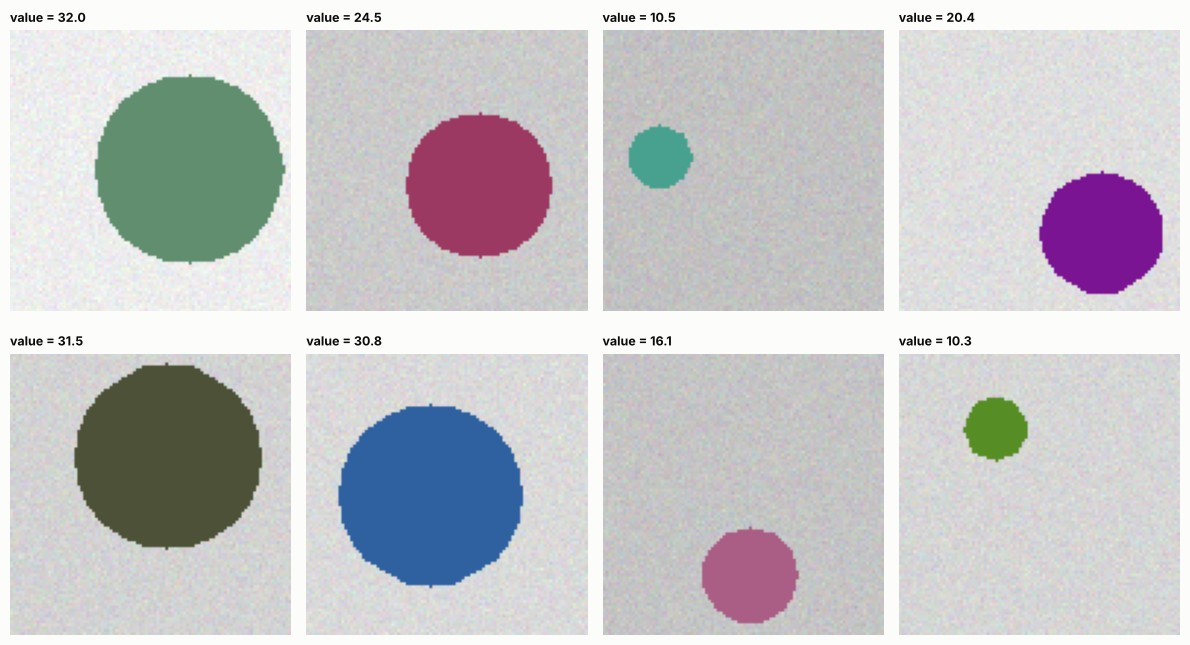

In [3]:
from PIL import Image
from cvkit.viz import image_grid
from tasks.regression.data import build_datasets

ds = build_datasets(cfg)
samples = ds["samples"]
picks = samples[:8]
_ = image_grid([Image.open(p) for p, _ in picks], [f"{ds['stats']['target_name']} = {v:.1f}" for _, v in picks], cols=4)

## 2 · Train
`train(cfg)` is the same function the command line calls: `python -m cvkit regression train --quick`. It prints one line per epoch and saves the best model.

In [4]:
from tasks.regression.train import train

result = train(cfg)

arch: resnet18 | target 'value': train mean 21.691, std 7.969
device: cpu | parameters: 11,177,025 total, 11,177,025 trainable (100.0%)


epoch   1/20 | train_loss 0.8155 | val mae=14.041 rmse=15.317 r2=-2.650 | 2.8s  <- best


epoch   2/20 | train_loss 0.1592 | val mae=3.817 rmse=5.316 r2=0.560 | 2.9s  <- best


epoch   3/20 | train_loss 0.0763 | val mae=2.131 rmse=2.624 r2=0.893 | 2.9s  <- best


epoch   4/20 | train_loss 0.0539 | val mae=1.042 rmse=1.302 r2=0.974 | 2.9s  <- best


...

epoch  16/20 | train_loss 0.0088 | val mae=0.397 rmse=0.515 r2=0.996 | 2.8s  <- best


epoch  17/20 | train_loss 0.0037 | val mae=0.314 rmse=0.417 r2=0.997 | 2.9s  <- best


epoch  18/20 | train_loss 0.0061 | val mae=0.318 rmse=0.400 r2=0.998 | 2.9s


epoch  19/20 | train_loss 0.0033 | val mae=0.350 rmse=0.435 r2=0.997 | 3.0s


epoch  20/20 | train_loss 0.0040 | val mae=0.307 rmse=0.385 r2=0.998 | 2.9s  <- best
best val mae = 0.3067 (epoch 20) -> outputs/regression_quick/checkpoints/best.pt


## 3 · Evaluate on the held-out test split
Images the model never trained on, and never used to pick its best epoch.

In [5]:
from tasks.regression.evaluate import evaluate

metrics = evaluate(cfg)

value: MAE 0.406 | RMSE 0.533 | R2 0.996 (68 images)
for reference, always guessing the train mean would give MAE 7.565
reports -> outputs/regression_quick/reports


pred_vs_true.png


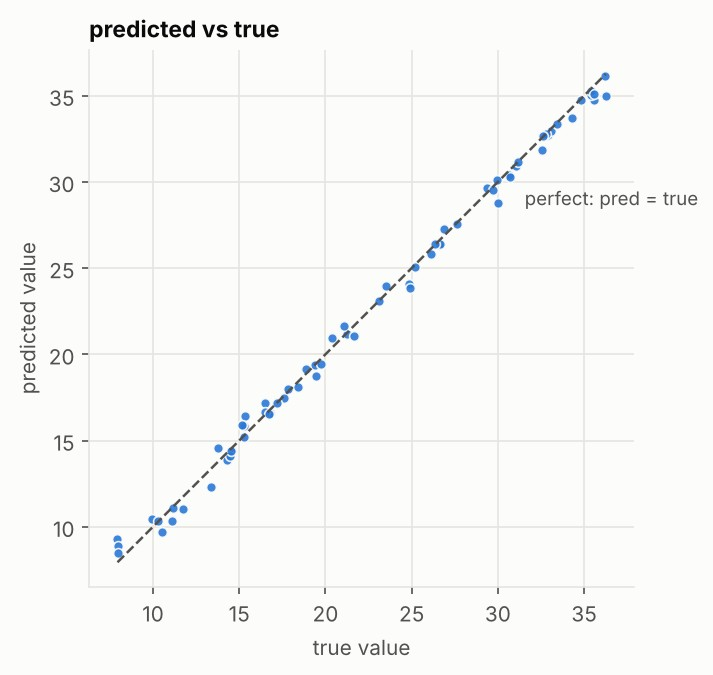

residuals.png


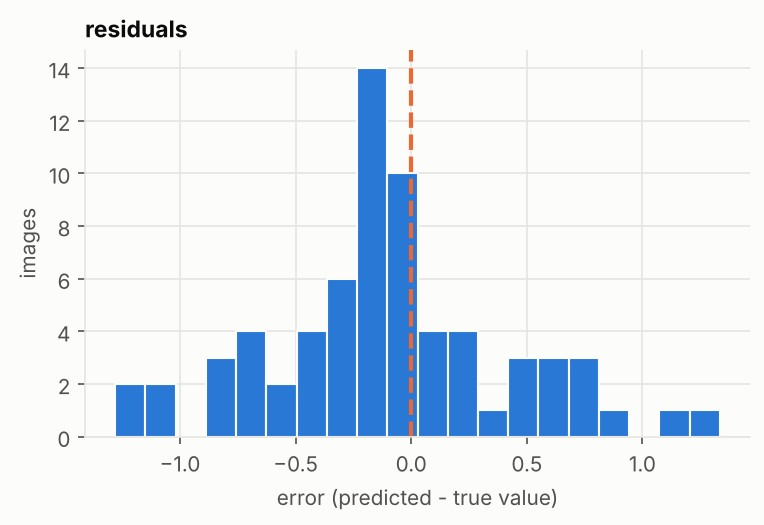

worst_errors.png


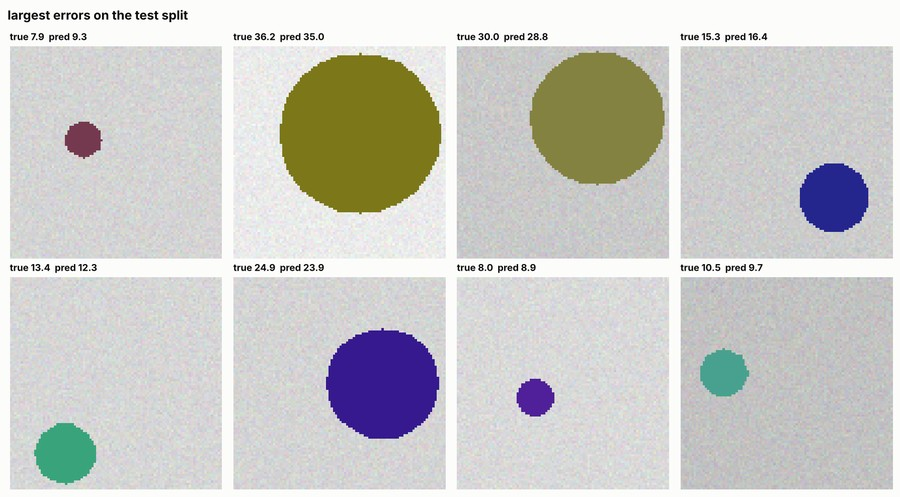

In [6]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['pred_vs_true.png', 'residuals.png', 'worst_errors.png']:
    print(name)
    show_image(reports / name)

**Reading it:** in `pred_vs_true.png` a perfect model puts every dot on the dashed diagonal. `residuals.png` should be a narrow bump centred on 0 — off-centre means a systematic bias. The printed *baseline MAE* is what you'd get by always guessing the average: a useful model must beat it clearly.

## 4 · Predict
`Predictor.predict` returns a single float, in the same units as your `labels.csv`:

In [7]:
from tasks.regression.predict import Predictor
from tasks.regression.data import build_datasets

predictor = Predictor.from_config(cfg)
test = build_datasets(cfg)["test"]
for path, true in test.samples[:5]:
    print(f"{Path(path).name}: predicted {predictor.predict(path):6.2f} | true {true:6.2f}")

img_0155.png: predicted  15.86 | true  15.29
img_0184.png: predicted  19.36 | true  19.38
img_0044.png: predicted  26.34 | true  26.60
img_0112.png: predicted  34.73 | true  34.80
img_0444.png: predicted  17.46 | true  17.58


## What next?
* **[01_data](01_data.ipynb)** — look at the data and augmentation properly
* **[02_train_and_evaluate](02_train_and_evaluate.ipynb)** — learning curves, how to read the metrics, experiments
* **[03_predict_and_deploy](03_predict_and_deploy.ipynb)** — your own images, the demo app, deployment
* Read the task's [README](../README.md) · use your own data: [data formats](../../../docs/data-formats.md)